/var/folders/v0/2w8lhx4x67x22b8p921g5s5w0000gn/T/ipykernel_9709/861250280.py:22: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df = pd.read_csv('upload_DJIA_table.csv', parse_dates=['Date'])


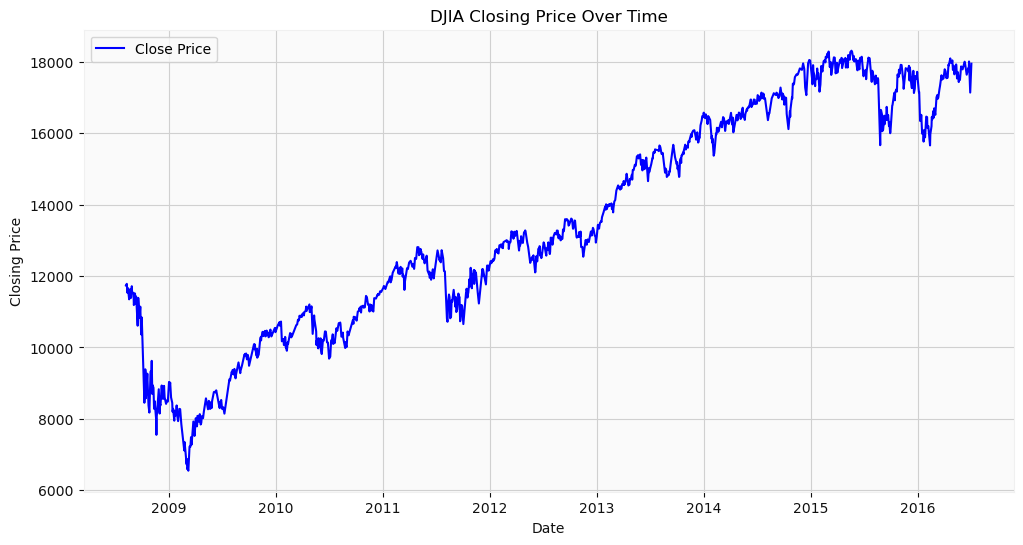

/Users/amritesh/Applications/Anaconda/anaconda3/lib/python3.11/site-packages/mplfinance/_arg_validators.py:84: UserWarning: 


            POSSIBLE TO SEE DETAILS (Candles, Ohlc-Bars, Etc.)
   For more information see:
   - https://github.com/matplotlib/mplfinance/wiki/Plotting-Too-Much-Data
   
   TO SILENCE THIS WARNING, set `type='line'` in `mpf.plot()`
   OR set kwarg `warn_too_much_data=N` where N is an integer 
   LARGER than the number of data points you want to plot.

  warnings.warn('\n\n ================================================================= '+


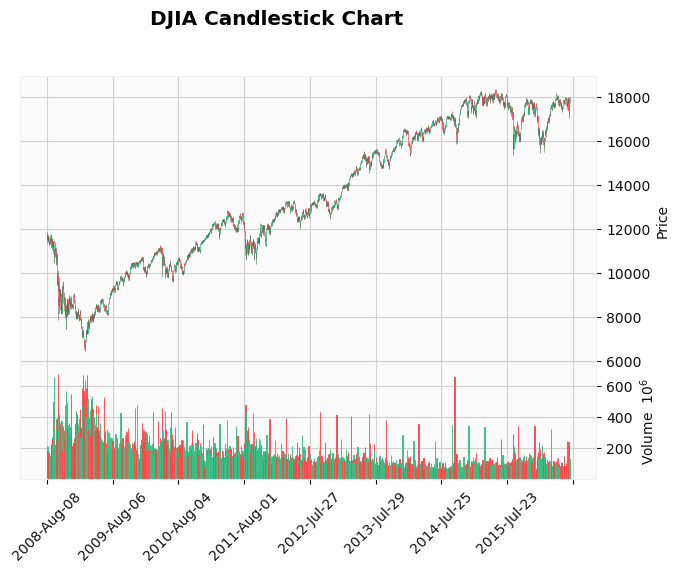

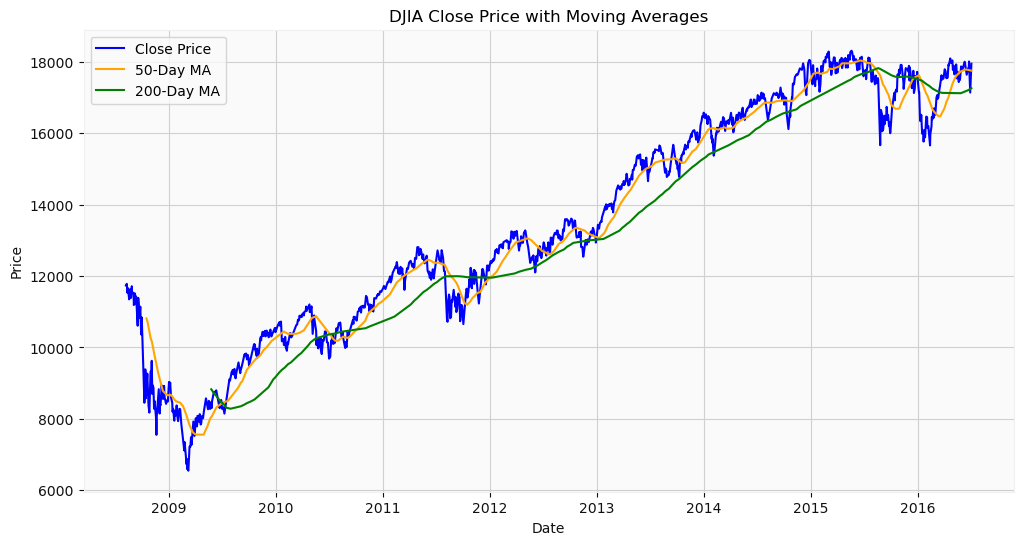

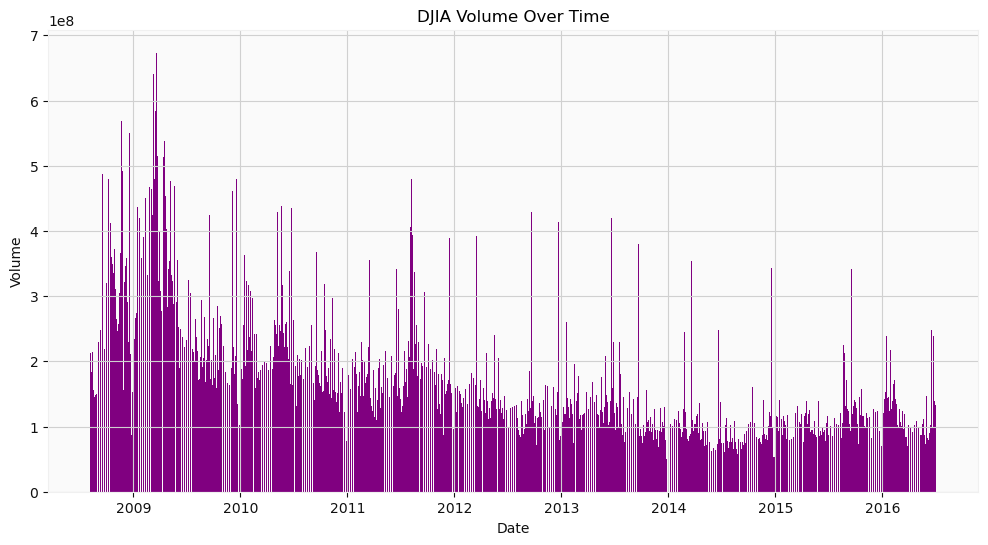

/Users/amritesh/Applications/Anaconda/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


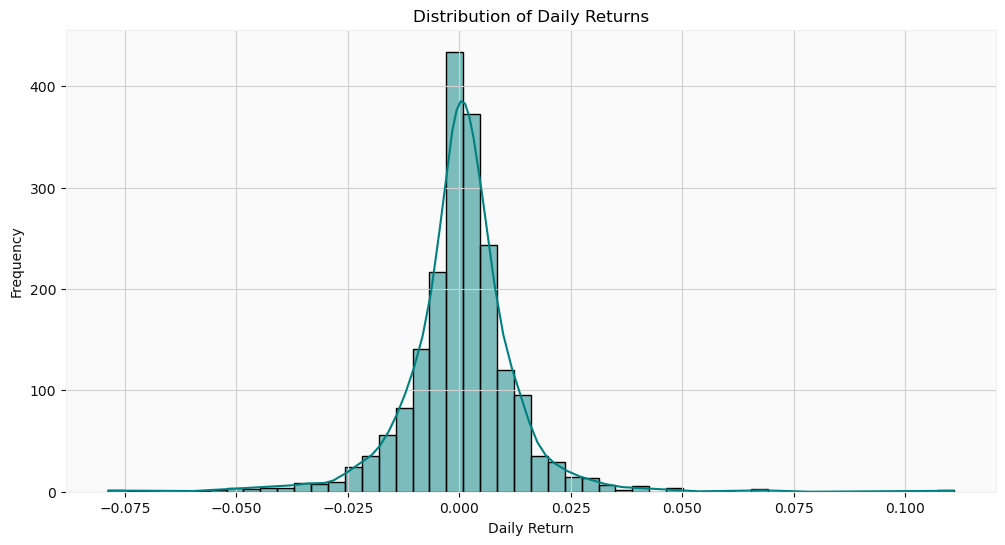

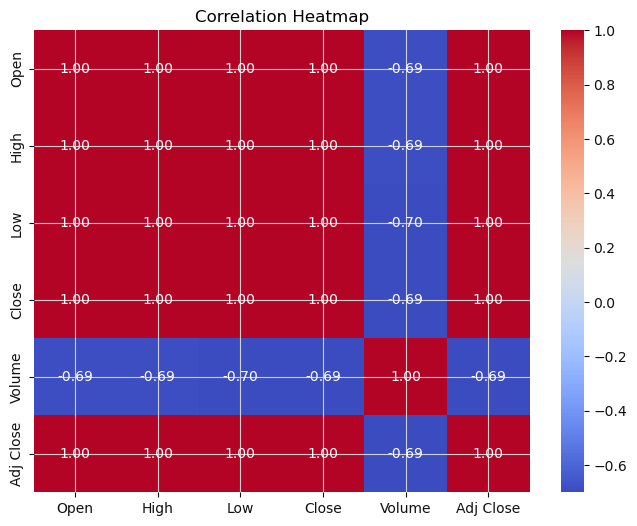

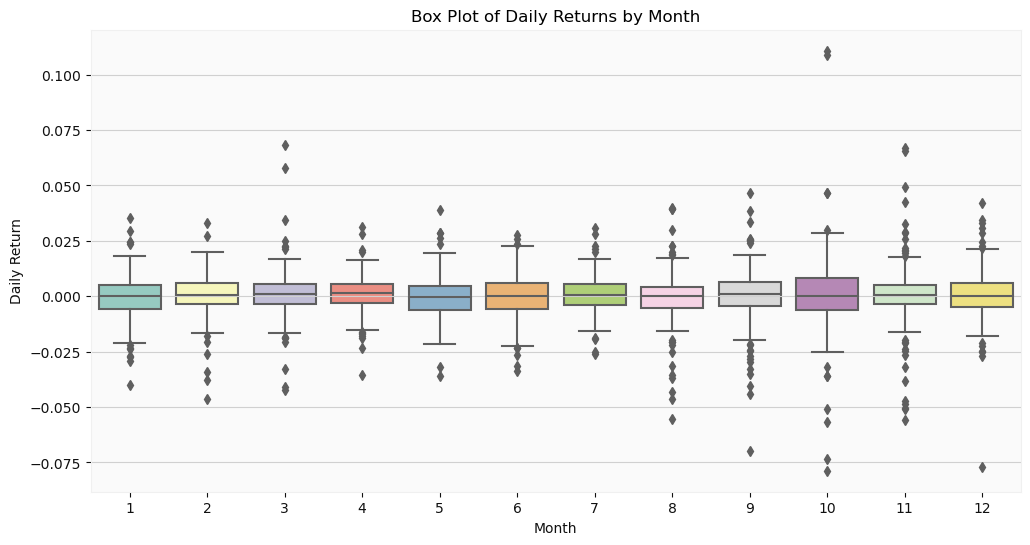

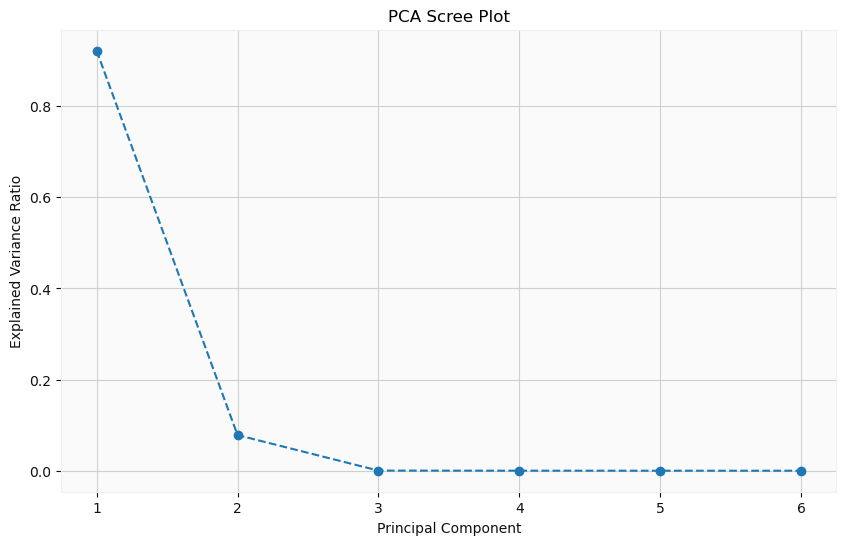

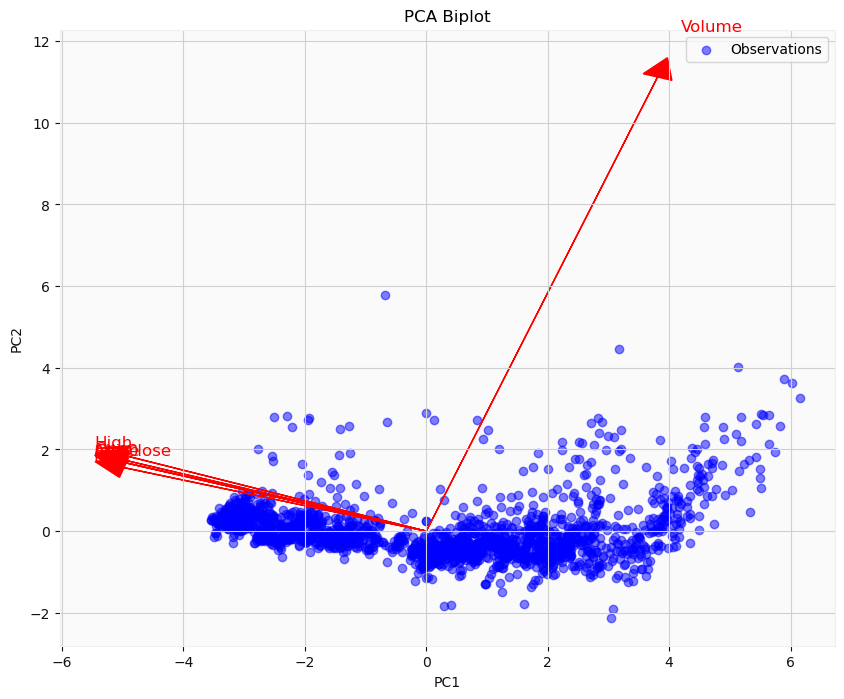

<Figure size 1000x600 with 0 Axes>

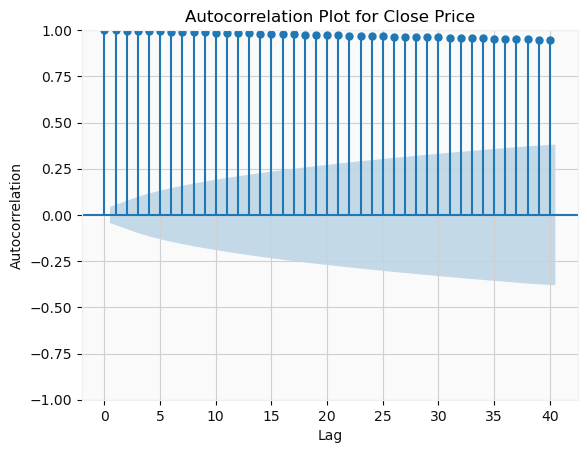

<Figure size 1000x600 with 0 Axes>

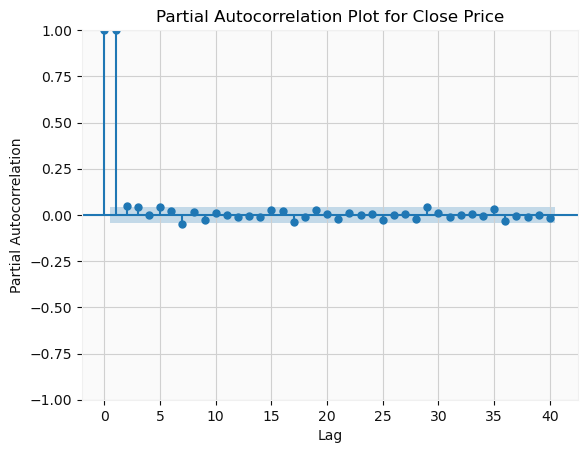

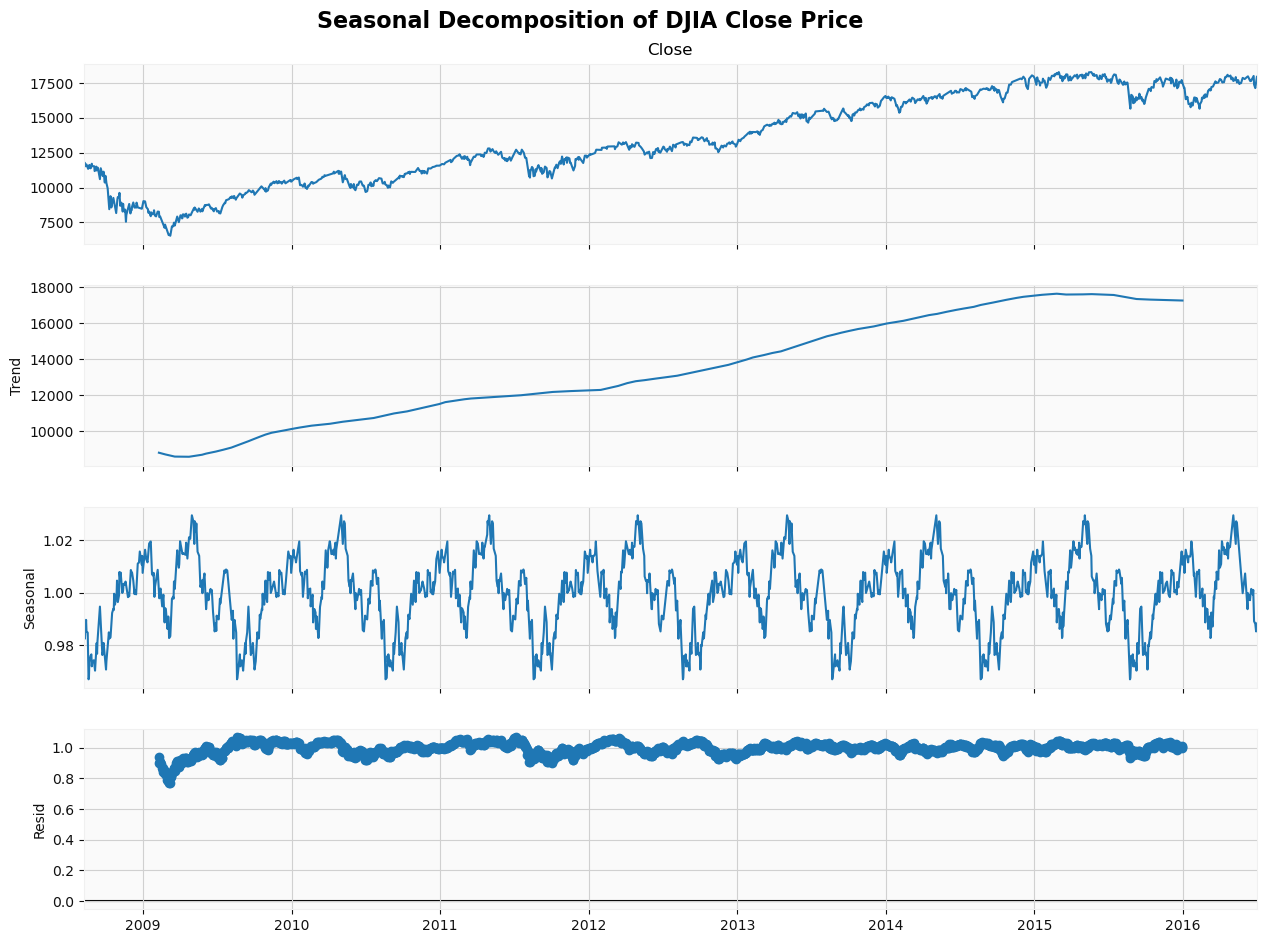

In [8]:
# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mplfinance as mpf
import numpy as np

# For PCA
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# For ACF/PACF and seasonal decomposition (helpful for LSTM)
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose

%matplotlib inline

# -----------------------------
# Data Reading & Preprocessing
# -----------------------------
df = pd.read_csv('upload_DJIA_table.csv', parse_dates=['Date'])
df.sort_values('Date', inplace=True)
df.set_index('Date', inplace=True)

# -----------------------------
# 1. Basic Exploratory Visualizations
# -----------------------------

# Time Series Line Chart of Closing Price
plt.figure(figsize=(12, 6))
plt.plot(df.index, df['Close'], label='Close Price', color='blue')
plt.title('DJIA Closing Price Over Time')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.legend()
plt.grid(True)
plt.show()

# Candlestick (OHLC) Chart with Volume using mplfinance
mpf.plot(df, type='candle', style='yahoo', volume=True, title='DJIA Candlestick Chart')

# Moving Averages Overlay (50-day and 200-day)
df['MA50'] = df['Close'].rolling(window=50).mean()
df['MA200'] = df['Close'].rolling(window=200).mean()

plt.figure(figsize=(12, 6))
plt.plot(df.index, df['Close'], label='Close Price', color='blue')
plt.plot(df.index, df['MA50'], label='50-Day MA', color='orange')
plt.plot(df.index, df['MA200'], label='200-Day MA', color='green')
plt.title('DJIA Close Price with Moving Averages')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.grid(True)
plt.show()

# Volume Over Time Chart
plt.figure(figsize=(12, 6))
plt.bar(df.index, df['Volume'], width=2, color='purple')
plt.title('DJIA Volume Over Time')
plt.xlabel('Date')
plt.ylabel('Volume')
plt.show()

# Distribution Histogram of Daily Returns
df['Daily_Return'] = df['Close'].pct_change()

plt.figure(figsize=(12, 6))
sns.histplot(df['Daily_Return'].dropna(), bins=50, kde=True, color='teal')
plt.title('Distribution of Daily Returns')
plt.xlabel('Daily Return')
plt.ylabel('Frequency')
plt.show()

# Correlation Heatmap of Key Variables
cols = ['Open', 'High', 'Low', 'Close', 'Volume', 'Adj Close']
corr = df[cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

# Box Plot of Daily Returns by Month
df['Month'] = df.index.month
plt.figure(figsize=(12, 6))
sns.boxplot(x='Month', y='Daily_Return', data=df, palette='Set3')
plt.title('Box Plot of Daily Returns by Month')
plt.xlabel('Month')
plt.ylabel('Daily Return')
plt.show()


# -----------------------------
# 2. Visualizations Tailored to PCA
# -----------------------------
features = ['Open', 'High', 'Low', 'Close', 'Volume', 'Adj Close']
data_features = df[features].dropna()

# Standardize the features before PCA
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data_features)

# Apply PCA
pca = PCA()
pca.fit(data_scaled)
explained_variance = pca.explained_variance_ratio_

# (a) PCA Scree Plot: Variance explained by each component
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(explained_variance)+1), explained_variance, marker='o', linestyle='--')
plt.title('PCA Scree Plot')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.xticks(range(1, len(explained_variance)+1))
plt.grid(True)
plt.show()

# (b) PCA Biplot: Projection on the first two principal components
# Compute the scores (transformed data) and loadings (component vectors)
scores = pca.transform(data_scaled)
loadings = pca.components_.T

plt.figure(figsize=(10, 8))
plt.scatter(scores[:, 0], scores[:, 1], alpha=0.5, color='blue', label='Observations')
# Scale arrows to fit the plot; adjust the factor as needed
arrow_size = 5 * np.std(scores[:, 0])
for i, feature in enumerate(features):
    plt.arrow(0, 0, loadings[i, 0]*arrow_size, loadings[i, 1]*arrow_size,
              color='red', head_width=0.5, head_length=0.5)
    plt.text(loadings[i, 0]*arrow_size*1.1, loadings[i, 1]*arrow_size*1.1,
             feature, color='red', fontsize=12)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA Biplot')
plt.legend()
plt.grid(True)
plt.show()


# -----------------------------
# 3. Visualizations Relevant to LSTM / Time Series Forecasting
# -----------------------------

# (a) Autocorrelation Plot for Close Price
plt.figure(figsize=(10, 6))
plot_acf(df['Close'].dropna(), lags=40)
plt.title('Autocorrelation Plot for Close Price')
plt.xlabel('Lag')
plt.ylabel('Autocorrelation')
plt.show()

# (b) Partial Autocorrelation Plot for Close Price
plt.figure(figsize=(10, 6))
plot_pacf(df['Close'].dropna(), lags=40, method='ywm')
plt.title('Partial Autocorrelation Plot for Close Price')
plt.xlabel('Lag')
plt.ylabel('Partial Autocorrelation')
plt.show()

# (c) Seasonal Decomposition of Close Price
# Ensure the index has a proper frequency (e.g., Business Day frequency)
df_close = df['Close'].asfreq('B')
# period=252 approximates the number of trading days in a year
decomposition = seasonal_decompose(df_close.dropna(), model='multiplicative', period=252)
fig = decomposition.plot()
fig.set_size_inches(14, 10)
plt.suptitle('Seasonal Decomposition of DJIA Close Price', fontsize=16)
plt.show()
